# Lesson 15 — Advanced Classifiers: Gradient Boosting, SVM and Model Comparison

**Objective:** Compare gradient boosting and support vector machines against baseline models on a real clinical dataset, using leakage-safe pipelines, early stopping and randomized hyperparameter search.

**Data:** Pima Indians Diabetes dataset (OpenML ID 37) — 768 adult female patients, 8 clinical measurements, binary diabetes outcome. Originally from the US National Institute of Diabetes and Digestive and Kidney Diseases. Used here for education only.

In [1]:
# Lesson 15 — Step 1: Load and inspect the data
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

# Download the dataset from OpenML (cached locally after the first run)
diabetes = fetch_openml(data_id=37, as_frame=True)
df = diabetes.frame.copy()

print("ORIGINAL COLUMNS:", list(df.columns))

# Rename the short OpenML codes to readable clinical names
df = df.rename(columns={
    "preg": "Pregnancies",
    "plas": "Glucose",
    "pres": "BloodPressure",
    "skin": "SkinThickness",
    "insu": "Insulin",
    "mass": "BMI",
    "pedi": "DiabetesPedigree",
    "age": "Age",
})

# Convert the text label into a 0/1 target: 1 = diabetes
df["Outcome"] = (df["class"] == "tested_positive").astype(int)
df = df.drop(columns="class")

print("\nDATASET SHAPE:", df.shape)

print("\nFIRST FIVE RECORDS:")
display(df.head())

print("\nCLASS DISTRIBUTION:")
print(df["Outcome"].value_counts())
print("\nDiabetes prevalence:", f"{df['Outcome'].mean():.1%}")

ORIGINAL COLUMNS: ['preg', 'plas', 'pres', 'skin', 'insu', 'mass', 'pedi', 'age', 'class']

DATASET SHAPE: (768, 9)

FIRST FIVE RECORDS:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



CLASS DISTRIBUTION:
Outcome
0    500
1    268
Name: count, dtype: int64

Diabetes prevalence: 34.9%


## Step 2 — Hidden Missing Values

Zero is not a physiologically possible value for glucose, blood pressure, skin thickness, insulin or BMI. In this dataset, zeros in these columns represent measurements that were not recorded, so they are converted to missing values (NaN) before modelling.

In [2]:
# Lesson 15 — Step 2: Detect and recode hidden missing values
features = df.columns.drop("Outcome")

print("SUMMARY STATISTICS:")
display(df[features].describe().round(1))

# Columns where a value of 0 is physiologically impossible
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_counts = pd.DataFrame({
    "Zeros": (df[zero_as_missing] == 0).sum(),
    "Zeros (%)": ((df[zero_as_missing] == 0).mean() * 100).round(1)
})
print("\nZERO VALUES IN CLINICAL MEASUREMENTS:")
display(zero_counts)

# Recode impossible zeros as missing values
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)

print("\nMISSING VALUES AFTER RECODING:")
print(df.isna().sum())

print("\nPatients with at least one missing value:",
      f"{df[features].isna().any(axis=1).sum()} of {len(df)}")

SUMMARY STATISTICS:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,3.8,120.9,69.1,20.5,79.8,32.0,0.5,33.2
std,3.4,32.0,19.4,16.0,115.2,7.9,0.3,11.8
min,0.0,0.0,0.0,0.0,0.0,0.0,0.1,21.0
25%,1.0,99.0,62.0,0.0,0.0,27.3,0.2,24.0
50%,3.0,117.0,72.0,23.0,30.5,32.0,0.4,29.0
75%,6.0,140.2,80.0,32.0,127.2,36.6,0.6,41.0
max,17.0,199.0,122.0,99.0,846.0,67.1,2.4,81.0



ZERO VALUES IN CLINICAL MEASUREMENTS:


,Zeros,Zeros (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4



MISSING VALUES AFTER RECODING:
Pregnancies           0
Glucose               5
BloodPressure        35
SkinThickness       227
Insulin             374
BMI                  11
DiabetesPedigree      0
Age                   0
Outcome               0
dtype: int64

Patients with at least one missing value: 376 of 768


## Step 3 — Train/Test Split and Baseline Models

The data is split once into a stratified 80/20 training and test set. The test set is held back until the final comparison. All model selection uses 5-fold stratified cross-validation on the training data only.

Missing values are filled with the training-fold median inside each pipeline, and a missing-value indicator is added for each affected column, because whether a test was recorded may itself be informative.

In [3]:
# Lesson 15 — Step 3: Train/test split and baseline models
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X = df[features]
y = df["Outcome"]

# Stratified split: the test set is held back until the final comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Training set:", X_train.shape, f"| prevalence {y_train.mean():.1%}")
print("Test set:    ", X_test.shape, f"| prevalence {y_test.mean():.1%}")

# Shared cross-validation setup, reused for every model in this lesson
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
    "Accuracy": "accuracy",
    "Recall": "recall",
    "F1": "f1",
}
cv_results = []

def evaluate_cv(name, model):
    """Cross-validate a model on the training data and store mean and SD per metric."""
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
        row[f"{metric} SD"] = scores[f"test_{metric}"].std()
    cv_results.append(row)
    return row

# Imputation step shared by all models: median + missing-value indicators
def imputer():
    return SimpleImputer(strategy="median", add_indicator=True)

baselines = {
    "Logistic Regression": Pipeline([
        ("imputer", imputer()),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", imputer()),
        ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    ]),
}

for name, model in baselines.items():
    evaluate_cv(name, model)

summary_cols = ["Model", "ROC-AUC", "ROC-AUC SD", "PR-AUC", "Accuracy", "Recall", "F1"]
print("\nBASELINE CROSS-VALIDATION RESULTS (training data, 5 folds):")
display(pd.DataFrame(cv_results)[summary_cols].round(3))

Training set: (614, 8) | prevalence 34.9%
Test set:     (154, 8) | prevalence 35.1%



BASELINE CROSS-VALIDATION RESULTS (training data, 5 folds):


,Model,ROC-AUC,ROC-AUC SD,PR-AUC,Accuracy,Recall,F1
0,Logistic Regression,0.839,0.023,0.746,0.790,0.598,0.665
1,Random Forest,0.822,0.024,0.713,0.757,0.570,0.621


## Step 4 — Gradient Boosting: Learning Rate vs Number of Trees

Gradient boosting adds shallow trees sequentially, each correcting the errors of the ensemble so far. The learning rate and the number of trees interact: a higher learning rate reaches its best performance with fewer trees but overfits sooner. Cross-validated ROC-AUC is tracked after every tree for four learning rates.

LEARNING RATE SUMMARY:


,Learning rate,Best no. of trees,Best CV ROC-AUC,CV ROC-AUC at 500 trees
0,0.01,220,0.828,0.822
1,0.05,40,0.828,0.812
2,0.10,25,0.826,0.807
3,0.30,13,0.821,0.793


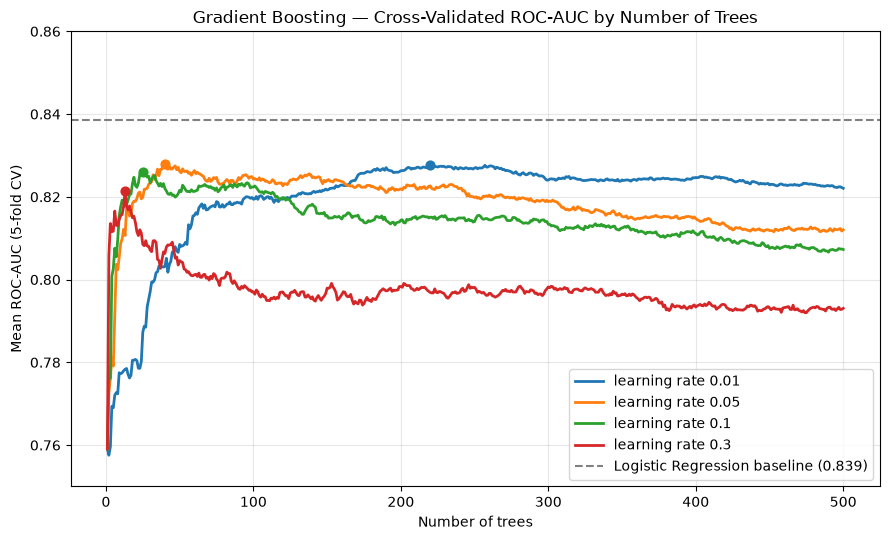


CROSS-VALIDATION RESULTS SO FAR:


,Model,ROC-AUC,ROC-AUC SD,PR-AUC,Accuracy,Recall,F1
0,Logistic Regression,0.839,0.023,0.746,0.790,0.598,0.665
1,Random Forest,0.822,0.024,0.713,0.757,0.570,0.621
2,Gradient Boosting (default),0.822,0.017,0.711,0.757,0.607,0.636


In [4]:
# Lesson 15 — Step 4: Learning rate vs number of trees (cross-validated)
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

learning_rates = [0.01, 0.05, 0.1, 0.3]
max_trees = 500
curves = {}

for lr in learning_rates:
    fold_scores = []
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        # Fit the imputer on the training fold only (no leakage)
        imp = imputer().fit(X_tr)
        gb = GradientBoostingClassifier(
            learning_rate=lr, n_estimators=max_trees, max_depth=3, random_state=42
        )
        gb.fit(imp.transform(X_tr), y_tr)

        # ROC-AUC on the validation fold after each additional tree
        staged = gb.staged_predict_proba(imp.transform(X_val))
        fold_scores.append([roc_auc_score(y_val, p[:, 1]) for p in staged])

    curves[lr] = np.mean(fold_scores, axis=0)

# Summary: where each learning rate peaks
lr_summary = pd.DataFrame([{
    "Learning rate": lr,
    "Best no. of trees": int(np.argmax(c)) + 1,
    "Best CV ROC-AUC": c.max(),
    f"CV ROC-AUC at {max_trees} trees": c[-1],
} for lr, c in curves.items()])
print("LEARNING RATE SUMMARY:")
display(lr_summary.round(3))

# Plot the learning curves against the Logistic Regression baseline
lr_baseline = pd.DataFrame(cv_results).set_index("Model").loc["Logistic Regression", "ROC-AUC"]
trees = np.arange(1, max_trees + 1)

fig, ax = plt.subplots(figsize=(9, 5.5))
for lr, c in curves.items():
    best = int(np.argmax(c))
    ax.plot(trees, c, linewidth=2, label=f"learning rate {lr}")
    ax.scatter(best + 1, c[best], s=40, zorder=3)
ax.axhline(lr_baseline, color="gray", linestyle="--", linewidth=1.5,
           label=f"Logistic Regression baseline ({lr_baseline:.3f})")
ax.set_title("Gradient Boosting — Cross-Validated ROC-AUC by Number of Trees")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Mean ROC-AUC (5-fold CV)")
ax.set_ylim(0.75, 0.86)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Add scikit-learn's default Gradient Boosting to the comparison table
evaluate_cv("Gradient Boosting (default)", Pipeline([
    ("imputer", imputer()),
    ("model", GradientBoostingClassifier(random_state=42)),
]))
print("\nCROSS-VALIDATION RESULTS SO FAR:")
display(pd.DataFrame(cv_results)[summary_cols].round(3))

## Step 5 — Early Stopping and Histogram-Based Gradient Boosting

Early stopping holds out part of each training fold and stops adding trees when validation loss stops improving, so the number of trees is chosen automatically without using the cross-validation folds. HistGradientBoostingClassifier is a faster implementation that handles missing values natively, learning at each split which branch missing values should follow.

In [5]:
# Lesson 15 — Step 5: Early stopping and HistGradientBoosting
from sklearn.ensemble import HistGradientBoostingClassifier

early_stopping_models = {
    "Gradient Boosting (early stopping)": Pipeline([
        ("imputer", imputer()),
        ("model", GradientBoostingClassifier(
            learning_rate=0.05, n_estimators=500,
            validation_fraction=0.15, n_iter_no_change=20,
            random_state=42)),
    ]),
    # No imputer: missing values are handled inside the model
    "HistGradientBoosting (early stopping)": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=500,
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
        random_state=42),
}

for name, model in early_stopping_models.items():
    evaluate_cv(name, model)

    # How many trees did early stopping keep in each fold?
    fitted = cross_validate(model, X_train, y_train, cv=cv,
                            scoring="roc_auc", return_estimator=True)["estimator"]
    final = [est[-1] if isinstance(est, Pipeline) else est for est in fitted]
    n_trees = [getattr(m, "n_estimators_", None) or m.n_iter_ for m in final]
    print(f"{name}: trees kept per fold = {n_trees}")

print("\nCROSS-VALIDATION RESULTS SO FAR:")
display(pd.DataFrame(cv_results)[summary_cols].round(3))

Gradient Boosting (early stopping): trees kept per fold = [94, 121, 60, 47, 80]


HistGradientBoosting (early stopping): trees kept per fold = [39, 63, 97, 59, 92]

CROSS-VALIDATION RESULTS SO FAR:


,Model,ROC-AUC,ROC-AUC SD,PR-AUC,Accuracy,Recall,F1
0,Logistic Regression,0.839,0.023,0.746,0.790,0.598,0.665
1,Random Forest,0.822,0.024,0.713,0.757,0.570,0.621
2,Gradient Boosting (default),0.822,0.017,0.711,0.757,0.607,0.636
3,Gradient Boosting (early stopping),0.824,0.029,0.715,0.754,0.561,0.614
4,HistGradientBoosting (early stopping),0.809,0.021,0.691,0.751,0.589,0.621


## Step 6 — Support Vector Machines: Kernels and Feature Scaling

A support vector machine finds the decision boundary with the widest margin between classes. A linear kernel gives a straight boundary; an RBF kernel allows a curved one. Because SVMs rely on distances between observations, features on large scales (such as insulin) dominate unless all features are standardised. Three SVMs are compared: RBF without scaling, RBF with scaling, and linear with scaling.

In [6]:
# Lesson 15 — Step 6: Support Vector Machines — kernels and scaling
from sklearn.svm import SVC

svm_models = {
    "SVM RBF (unscaled)": Pipeline([
        ("imputer", imputer()),
        ("model", SVC(kernel="rbf", random_state=42)),
    ]),
    "SVM RBF (scaled)": Pipeline([
        ("imputer", imputer()),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", random_state=42)),
    ]),
    "SVM linear (scaled)": Pipeline([
        ("imputer", imputer()),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", random_state=42)),
    ]),
}

for name, model in svm_models.items():
    evaluate_cv(name, model)

print("CROSS-VALIDATION RESULTS SO FAR:")
display(pd.DataFrame(cv_results)[summary_cols].round(3))

# Feature scales the unscaled SVM is working with
print("\nFEATURE RANGES (training data) — why scaling matters for SVM:")
display((X_train.max() - X_train.min()).round(1).sort_values(ascending=False).to_frame("Range"))

CROSS-VALIDATION RESULTS SO FAR:


,Model,ROC-AUC,ROC-AUC SD,PR-AUC,Accuracy,Recall,F1
0,Logistic Regression,0.839,0.023,0.746,0.790,0.598,0.665
1,Random Forest,0.822,0.024,0.713,0.757,0.570,0.621
2,Gradient Boosting (default),0.822,0.017,0.711,0.757,0.607,0.636
3,Gradient Boosting (early stopping),0.824,0.029,0.715,0.754,0.561,0.614
4,HistGradientBoosting (early stopping),0.809,0.021,0.691,0.751,0.589,0.621
5,SVM RBF (unscaled),0.824,0.028,0.741,0.769,0.505,0.603
6,SVM RBF (scaled),0.833,0.013,0.732,0.769,0.566,0.630
7,SVM linear (scaled),0.843,0.018,0.750,0.785,0.575,0.650



FEATURE RANGES (training data) — why scaling matters for SVM:


,Range
Insulin,729.0
Glucose,143.0
BloodPressure,98.0
SkinThickness,92.0
Age,60.0
BMI,48.9
Pregnancies,17.0
DiabetesPedigree,2.2


## Step 7 — Hyperparameter Tuning with RandomizedSearchCV

Randomized search samples a fixed number of hyperparameter combinations from specified distributions, which scales better than an exhaustive grid. Each model family receives the same budget (30 sampled combinations), the same cross-validation folds and the same metric (ROC-AUC). Continuous parameters such as C and the learning rate are sampled on a log scale, because their effect is multiplicative.

In [7]:
# Lesson 15 — Step 7: Hyperparameter tuning with RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

search_spaces = {
    "Logistic Regression (tuned)": (
        baselines["Logistic Regression"],
        {"model__C": loguniform(1e-3, 1e2)},
    ),
    "SVM linear (tuned)": (
        svm_models["SVM linear (scaled)"],
        {"model__C": loguniform(1e-3, 1e2)},
    ),
    "SVM RBF (tuned)": (
        svm_models["SVM RBF (scaled)"],
        {"model__C": loguniform(1e-2, 1e2),
         "model__gamma": loguniform(1e-4, 1e0)},
    ),
    "Gradient Boosting (tuned)": (
        Pipeline([("imputer", imputer()),
                  ("model", GradientBoostingClassifier(random_state=42))]),
        {"model__learning_rate": loguniform(0.01, 0.3),
         "model__n_estimators": randint(30, 400),
         "model__max_depth": randint(1, 5),
         "model__subsample": uniform(0.6, 0.4),
         "model__min_samples_leaf": randint(1, 30)},
    ),
}

tuned_models = {}
for name, (pipeline, params) in search_spaces.items():
    search = RandomizedSearchCV(
        pipeline, params, n_iter=30, cv=cv, scoring="roc_auc",
        random_state=42, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    best = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
            for k, v in search.best_params_.items()}
    print(f"{name}: best CV ROC-AUC = {search.best_score_:.3f} | {best}")
    evaluate_cv(name, search.best_estimator_)

print("\nALL CROSS-VALIDATION RESULTS (sorted by ROC-AUC):")
display(pd.DataFrame(cv_results)[summary_cols]
        .sort_values("ROC-AUC", ascending=False).round(3).reset_index(drop=True))

Logistic Regression (tuned): best CV ROC-AUC = 0.841 | {'C': np.float64(0.0332)}


SVM linear (tuned): best CV ROC-AUC = 0.845 | {'C': np.float64(0.006)}


SVM RBF (tuned): best CV ROC-AUC = 0.845 | {'C': np.float64(21.3683), 'gamma': np.float64(0.0007)}


Gradient Boosting (tuned): best CV ROC-AUC = 0.840 | {'learning_rate': np.float64(0.0504), 'max_depth': 1, 'min_samples_leaf': 4, 'n_estimators': 251, 'subsample': np.float64(0.6557)}



ALL CROSS-VALIDATION RESULTS (sorted by ROC-AUC):


,Model,ROC-AUC,ROC-AUC SD,PR-AUC,Accuracy,Recall,F1
0,SVM linear (tuned),0.845,0.011,0.743,0.774,0.500,0.606
1,SVM RBF (tuned),0.845,0.018,0.754,0.775,0.533,0.623
2,SVM linear (scaled),0.843,0.018,0.750,0.785,0.575,0.650
3,Logistic Regression (tuned),0.841,0.017,0.741,0.782,0.561,0.642
4,Gradient Boosting (tuned),0.840,0.026,0.741,0.780,0.566,0.642
5,Logistic Regression,0.839,0.023,0.746,0.790,0.598,0.665
6,SVM RBF (scaled),0.833,0.013,0.732,0.769,0.566,0.630
7,Gradient Boosting (early stopping),0.824,0.029,0.715,0.754,0.561,0.614
8,SVM RBF (unscaled),0.824,0.028,0.741,0.769,0.505,0.603
9,Gradient Boosting (default),0.822,0.017,0.711,0.757,0.607,0.636


## Step 8 — Final Evaluation on the Held-Out Test Set

Four finalists were selected from cross-validation alone, one tuned model per family. Each is refitted on the full training set and evaluated once on the 154 held-out patients, at the default decision threshold.

TEST SET RESULTS (n = 154, 54 with diabetes, threshold = default):


,Model,ROC-AUC,PR-AUC,Accuracy,Sensitivity,Specificity,Precision,F1,Missed cases
0,Gradient Boosting (tuned),0.825,0.702,0.760,0.593,0.85,0.681,0.634,22
1,SVM RBF (tuned),0.818,0.690,0.727,0.500,0.85,0.643,0.562,27
2,Logistic Regression (tuned),0.813,0.674,0.721,0.556,0.81,0.612,0.583,24
3,SVM linear (tuned),0.807,0.660,0.753,0.500,0.89,0.711,0.587,27


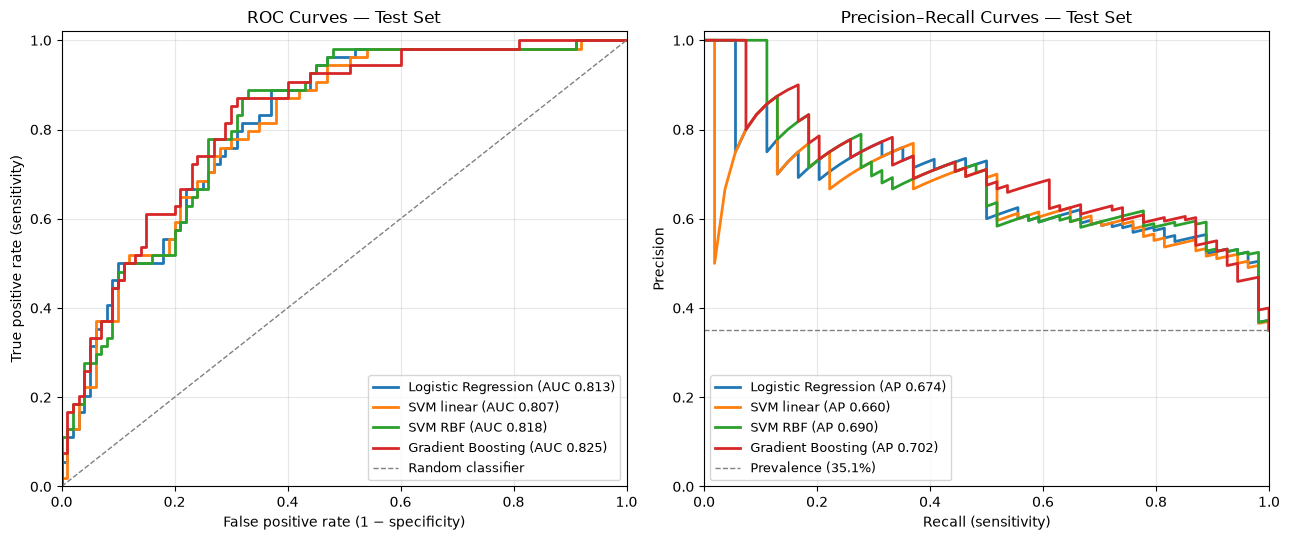

In [8]:
# Lesson 15 — Step 8: Final evaluation on the held-out test set
from sklearn.metrics import (average_precision_score, accuracy_score, recall_score,
                             precision_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

finalists = ["Logistic Regression (tuned)", "SVM linear (tuned)",
             "SVM RBF (tuned)", "Gradient Boosting (tuned)"]

def risk_score(model, X):
    """Probability if available, otherwise the SVM's distance to the boundary."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

test_rows, test_scores = [], {}
for name in finalists:
    model = tuned_models[name].fit(X_train, y_train)
    scores = risk_score(model, X_test)
    preds = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    test_scores[name] = scores
    test_rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC": average_precision_score(y_test, scores),
        "Accuracy": accuracy_score(y_test, preds),
        "Sensitivity": recall_score(y_test, preds),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "Missed cases": fn,
    })

test_df = pd.DataFrame(test_rows).sort_values("ROC-AUC", ascending=False)
print(f"TEST SET RESULTS (n = {len(y_test)}, {y_test.sum()} with diabetes, threshold = default):")
display(test_df.round(3).reset_index(drop=True))

# ROC and precision-recall curves on the test set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    prec, rec, _ = precision_recall_curve(y_test, scores)
    ax1.plot(fpr, tpr, linewidth=2,
             label=f"{name.replace(' (tuned)', '')} (AUC {roc_auc_score(y_test, scores):.3f})")
    ax2.plot(rec, prec, linewidth=2,
             label=f"{name.replace(' (tuned)', '')} (AP {average_precision_score(y_test, scores):.3f})")

ax1.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Random classifier")
ax1.set(title="ROC Curves — Test Set", xlabel="False positive rate (1 − specificity)",
        ylabel="True positive rate (sensitivity)", xlim=(0, 1), ylim=(0, 1.02))
ax2.axhline(y_test.mean(), color="gray", linestyle="--", linewidth=1,
            label=f"Prevalence ({y_test.mean():.1%})")
ax2.set(title="Precision–Recall Curves — Test Set", xlabel="Recall (sensitivity)",
        ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left" if ax is ax2 else "lower right", fontsize=9)
plt.tight_layout()
plt.show()

## Step 9 — Uncertainty and Screening Threshold

Bootstrap resampling of the test set (2,000 resamples) gives 95% confidence intervals for each model's ROC-AUC and for the difference between the best-ranked model and Logistic Regression. Where models are statistically indistinguishable, the simplest interpretable model is preferred. A screening threshold targeting at least 85% sensitivity is then chosen from out-of-fold predictions on the training data, and applied once to the test set.

In [9]:
# Lesson 15 — Step 9: Bootstrap confidence intervals and screening threshold
from sklearn.model_selection import cross_val_predict

# --- 9a. Bootstrap 95% confidence intervals for test ROC-AUC ---
rng = np.random.default_rng(42)
y_true = y_test.to_numpy()
boot = {name: [] for name in test_scores}
diff = []

for _ in range(2000):
    idx = rng.integers(0, len(y_true), len(y_true))
    if y_true[idx].min() == y_true[idx].max():
        continue  # skip resamples that contain only one class
    aucs = {name: roc_auc_score(y_true[idx], s[idx]) for name, s in test_scores.items()}
    for name in test_scores:
        boot[name].append(aucs[name])
    diff.append(aucs["Gradient Boosting (tuned)"] - aucs["Logistic Regression (tuned)"])

ci_df = pd.DataFrame([{
    "Model": name,
    "Test ROC-AUC": roc_auc_score(y_true, test_scores[name]),
    "95% CI lower": np.percentile(boot[name], 2.5),
    "95% CI upper": np.percentile(boot[name], 97.5),
} for name in test_scores]).sort_values("Test ROC-AUC", ascending=False)
print("TEST ROC-AUC WITH 95% BOOTSTRAP CONFIDENCE INTERVALS:")
display(ci_df.round(3).reset_index(drop=True))

lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"Gradient Boosting − Logistic Regression: {np.mean(diff):+.3f} "
      f"(95% CI {lo:+.3f} to {hi:+.3f})")
print("→ Interval includes 0: no evidence of a real difference." if lo < 0 < hi
      else "→ Interval excludes 0: the difference is likely real.")

# --- 9b. Screening threshold for the final model, chosen on training data only ---
final_name = "Logistic Regression (tuned)"
final_model = tuned_models[final_name]
target_sensitivity = 0.85

oof_prob = cross_val_predict(final_model, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]

def sens_spec(y, prob, t):
    tn, fp, fn, tp = confusion_matrix(y, (prob >= t).astype(int)).ravel()
    return tp / (tp + fn), tn / (tn + fp)

candidates = np.round(np.arange(0.05, 0.96, 0.01), 2)
cv_sens = np.array([sens_spec(y_train, oof_prob, t)[0] for t in candidates])
threshold = candidates[cv_sens >= target_sensitivity].max()
cv_s, cv_sp = sens_spec(y_train, oof_prob, threshold)
print(f"\nThreshold chosen on training data: {threshold:.2f} "
      f"(CV sensitivity {cv_s:.3f}, specificity {cv_sp:.3f})")

# Apply once to the held-out test set, compared with the default 0.50
test_prob = final_model.predict_proba(X_test)[:, 1]
rows = []
for label, t in [("Default (0.50)", 0.50), (f"Screening ({threshold:.2f})", threshold)]:
    tn, fp, fn, tp = confusion_matrix(y_test, (test_prob >= t).astype(int)).ravel()
    rows.append({"Threshold": label, "Sensitivity": tp / (tp + fn),
                 "Specificity": tn / (tn + fp), "Precision": tp / (tp + fp),
                 "Missed cases": fn, "False alarms": fp})
print(f"\n{final_name.upper()} ON THE TEST SET:")
display(pd.DataFrame(rows).round(3))

TEST ROC-AUC WITH 95% BOOTSTRAP CONFIDENCE INTERVALS:


,Model,Test ROC-AUC,95% CI lower,95% CI upper
0,Gradient Boosting (tuned),0.825,0.751,0.883
1,SVM RBF (tuned),0.818,0.744,0.878
2,Logistic Regression (tuned),0.813,0.737,0.874
3,SVM linear (tuned),0.807,0.731,0.868


Gradient Boosting − Logistic Regression: +0.013 (95% CI -0.011 to +0.037)
→ Interval includes 0: no evidence of a real difference.



Threshold chosen on training data: 0.26 (CV sensitivity 0.860, specificity 0.605)

LOGISTIC REGRESSION (TUNED) ON THE TEST SET:


,Threshold,Sensitivity,Specificity,Precision,Missed cases,False alarms
0,Default (0.50),0.556,0.81,0.612,24,19
1,Screening (0.26),0.889,0.62,0.558,6,38


## Step 10 — Publication Figures

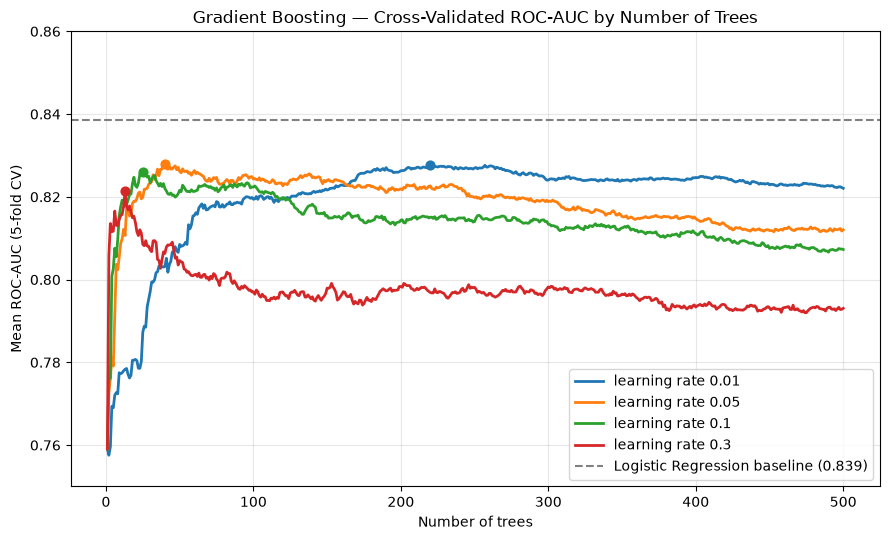

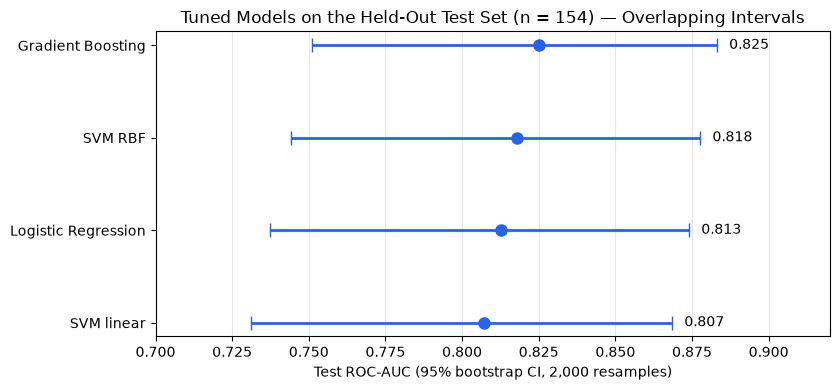

Saved: ['lesson15_gb_learning_rate_curves.png', 'lesson15_test_auc_confidence_intervals.png']


In [10]:
# Lesson 15 — Step 10: Save publication figures to figures/
from pathlib import Path

# Works whether the notebook runs from the repository root or from lessons/
fig_dir = Path("figures") if Path("figures").exists() else Path("..") / "figures"

# Figure 1: Gradient Boosting learning-rate curves (from Step 4)
fig, ax = plt.subplots(figsize=(9, 5.5))
for lr, c in curves.items():
    best = int(np.argmax(c))
    ax.plot(trees, c, linewidth=2, label=f"learning rate {lr}")
    ax.scatter(best + 1, c[best], s=40, zorder=3)
ax.axhline(lr_baseline, color="gray", linestyle="--", linewidth=1.5,
           label=f"Logistic Regression baseline ({lr_baseline:.3f})")
ax.set_title("Gradient Boosting — Cross-Validated ROC-AUC by Number of Trees")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Mean ROC-AUC (5-fold CV)")
ax.set_ylim(0.75, 0.86)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(fig_dir / "lesson15_gb_learning_rate_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: Test ROC-AUC with 95% bootstrap confidence intervals
order = ci_df.sort_values("Test ROC-AUC")
ypos = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.errorbar(order["Test ROC-AUC"], ypos,
            xerr=[order["Test ROC-AUC"] - order["95% CI lower"],
                  order["95% CI upper"] - order["Test ROC-AUC"]],
            fmt="o", markersize=8, capsize=5, linewidth=2, color="#2563EB")
for y_i, (auc, hi_ci) in enumerate(zip(order["Test ROC-AUC"], order["95% CI upper"])):
    ax.text(hi_ci + 0.004, y_i, f"{auc:.3f}", va="center", fontsize=10)
ax.set_yticks(ypos, order["Model"].str.replace(" (tuned)", ""))
ax.set_xlim(0.70, 0.92)
ax.set_xlabel("Test ROC-AUC (95% bootstrap CI, 2,000 resamples)")
ax.set_title(f"Tuned Models on the Held-Out Test Set (n = {len(y_test)}) — Overlapping Intervals")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
fig.savefig(fig_dir / "lesson15_test_auc_confidence_intervals.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", sorted(p.name for p in fig_dir.glob("lesson15_*.png")))

## Conclusions

1. **No model was meaningfully better.** After tuning, every model family reached a cross-validated ROC-AUC of 0.840–0.845. On the 154-patient test set, scores ranged from 0.807 to 0.825, with overlapping 95% bootstrap intervals. Gradient Boosting's lead over Logistic Regression was +0.013 (95% CI −0.011 to +0.037).
2. **Tuning favoured simplicity in every family.** It chose strong regularisation for Logistic Regression (C = 0.033) and the linear SVM (C = 0.006), a very smooth RBF kernel (gamma = 0.0007), and single-split trees for Gradient Boosting (max_depth = 1). This points to a largely linear relationship between the clinical measurements and diabetes.
3. **Learning rate and number of trees interact.** Higher learning rates peaked earlier and overfitted more: at 0.3, ROC-AUC peaked at 13 trees (0.821) and fell to 0.793 by 500 trees. At 0.01, it peaked at 220 trees (0.828) and declined only slightly. Early stopping chose 39–121 trees per fold, a noisy choice on small folds.
4. **Scaling is essential for SVMs.** Standardising features raised RBF SVM ROC-AUC from 0.824 to 0.833 and halved its variation across folds (SD 0.028 → 0.013).
5. **Final model and threshold.** Logistic Regression was selected as the simplest interpretable model, statistically tied with the best. A screening threshold of 0.26, chosen on training data only, raised test sensitivity from 0.556 to 0.889. Missed diabetic patients fell from 24 to 6, while false alarms rose from 19 to 38.

**Limitations:** a small dataset (768 patients) from a single population (adult women of Pima heritage), a 154-patient test set, and no external validation. Results are for learning purposes only, not clinical use.